In [9]:
import os
import copy
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_curve, roc_auc_score

# PARAMETRI

In [10]:
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.01        # learning rate di default dell'SGD di Keras, usato nel notebook originale
CHECKPOINT_EVERY = 10       # ogni quante epoche salvare i pesi (EPOCHS deve esserne un multiplo)
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [12]:
# DATASET SINTETICO: gaussiana standard in 10D, con alcune anomalie (media spostata) mescolate nel training set
D = 10
N = 500
N_ANOMALIES = 10
SHIFT = 1.75

rng = np.random.default_rng(0)
mean, cov = np.zeros(D), np.eye(D)
x_normal = rng.multivariate_normal(mean, cov, N - N_ANOMALIES)
anomalies = rng.multivariate_normal(mean + SHIFT, cov, N_ANOMALIES)
x_train = np.concatenate((anomalies, x_normal))                    # le anomalie sono i primi N_ANOMALIES punti
y_train = np.array([1] * N_ANOMALIES + [0] * (N - N_ANOMALIES))   # 1 = anomalia, 0 = normale (non usate nel training)

# Non c'è un test set: l'autoencoder si addestra sui dati contaminati e l'outlierness si calcola sugli stessi dati
train_dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)   # stessi dati, in ordine, per la valutazione

print(f"TRAIN SET shape: {x_train.shape}  ({N_ANOMALIES} anomalie)")

TRAIN SET shape: (500, 10)  (10 anomalie)


# MODELLO

In [4]:
#Parametri del modello
INPUT_SIZE = D      # 10
LATENT_SIZE = 2

In [5]:
encoder = nn.Sequential(
    nn.Linear(INPUT_SIZE, LATENT_SIZE), nn.ReLU(),   # (B, 10) -> (B, 2)
)

decoder = nn.Sequential(
    nn.Linear(LATENT_SIZE, INPUT_SIZE),              # (B, 2) -> (B, 10), uscita lineare: i dati non sono limitati
)

autoencoder = nn.Sequential(encoder, decoder).to(DEVICE)

# Versione equivalente come classe:
# class AutoEncoder(nn.Module):
#     def __init__(self, input_size, latent_size):
#         super().__init__()
#         self.encoder = nn.Sequential(nn.Linear(input_size, latent_size), nn.ReLU())
#         self.decoder = nn.Sequential(nn.Linear(latent_size, input_size))
#     def forward(self, x):
#         return self.decoder(self.encoder(x))
# autoencoder = AutoEncoder(INPUT_SIZE, LATENT_SIZE).to(DEVICE)
# encoder = autoencoder.encoder

optimizer = torch.optim.SGD(autoencoder.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

autoencoder

Sequential(
  (0): Sequential(
    (0): Linear(in_features=10, out_features=2, bias=True)
    (1): ReLU()
  )
  (1): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
  )
)

# ADDESTRAMENTO

100%|██████████| 10/10 [00:00<00:00, 25.74it/s]


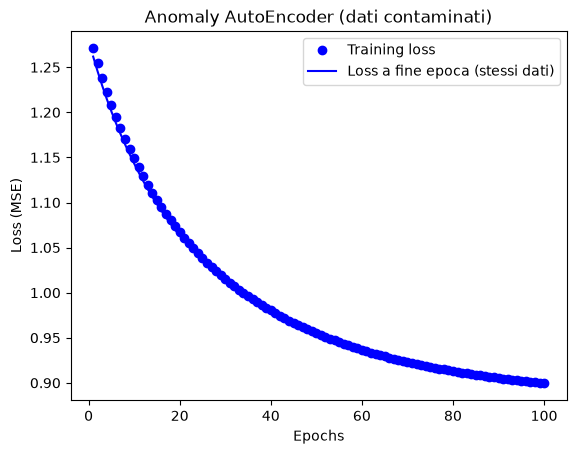

In [6]:
os.makedirs('histories', exist_ok=True)

filename = "anomaly2"
hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'
ckpt_path = f'histories/{filename}_checkpoints.pt'

if os.path.isfile(hist_path) and os.path.isfile(weights_path) and os.path.isfile(ckpt_path):
    with open(hist_path, 'rb') as hist_file:
        history_dict = pickle.load(hist_file)
    autoencoder.load_state_dict(torch.load(weights_path, map_location=DEVICE))
    checkpoints = torch.load(ckpt_path, map_location=DEVICE)
else:
    # Addestramento a blocchi di CHECKPOINT_EVERY epoche, salvando i pesi alla fine di ogni blocco
    assert EPOCHS % CHECKPOINT_EVERY == 0, "EPOCHS deve essere un multiplo di CHECKPOINT_EVERY"
    history_dict = {'loss': [], 'val_loss': []}
    checkpoints = {}
    for epoch in range(CHECKPOINT_EVERY, EPOCHS + 1, CHECKPOINT_EVERY):
        h = utils.train_autoencoder(autoencoder, optimizer, criterion,
                                    train_loader, test_loader, CHECKPOINT_EVERY, DEVICE)
        for k in history_dict:
            history_dict[k].extend(h[k])
        checkpoints[epoch] = copy.deepcopy(autoencoder.state_dict())
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(autoencoder.state_dict(), weights_path)
    torch.save(checkpoints, ckpt_path)

epochs = range(1, len(history_dict['loss']) + 1)
plt.figure()
plt.plot(epochs, history_dict['loss'], 'bo', label='Training loss')
plt.plot(epochs, history_dict['val_loss'], 'b', label='Loss a fine epoca (stessi dati)')
plt.title('Anomaly AutoEncoder (dati contaminati)')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend(loc='upper right')
plt.show()

# VALUTAZIONE

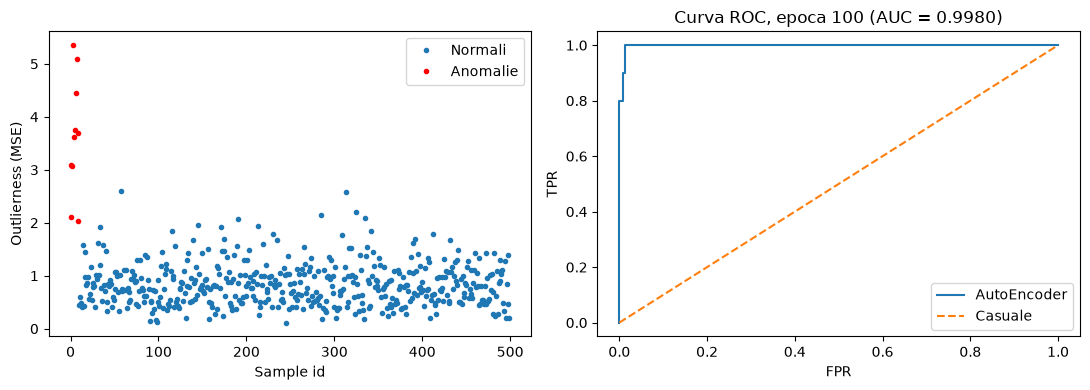

In [7]:
# ANOMALY DETECTION con il modello finale: l'outlierness di un punto è il suo errore di ricostruzione (MSE)
def compute_outlierness(model, loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x_rec = model(x.to(DEVICE)).cpu()
            scores.append(((x_rec - x) ** 2).mean(dim=1))   # MSE di ogni singolo punto
            labels.append(y)
    return torch.cat(scores).numpy(), torch.cat(labels).numpy()

outlierness, labels = compute_outlierness(autoencoder, test_loader)
fpr, tpr, thresholds = roc_curve(labels, outlierness)
auc = roc_auc_score(labels, outlierness)

ids = np.arange(len(outlierness))
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(ids[labels == 0], outlierness[labels == 0], '.', label='Normali')
plt.plot(ids[labels == 1], outlierness[labels == 1], '.', color='red', label='Anomalie')
plt.xlabel('Sample id')
plt.ylabel('Outlierness (MSE)')
plt.legend(loc='upper right')
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, label='AutoEncoder')
plt.plot([0, 1], [0, 1], linestyle='--', label='Casuale')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title(f'Curva ROC, epoca {EPOCHS} (AUC = {auc:.4f})')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Epoch  10: AUC = 0.9876
Epoch  20: AUC = 0.9933
Epoch  30: AUC = 0.9963
Epoch  40: AUC = 0.9976
Epoch  50: AUC = 0.9978
Epoch  60: AUC = 0.9986
Epoch  70: AUC = 0.9984
Epoch  80: AUC = 0.9984
Epoch  90: AUC = 0.9982
Epoch 100: AUC = 0.9980


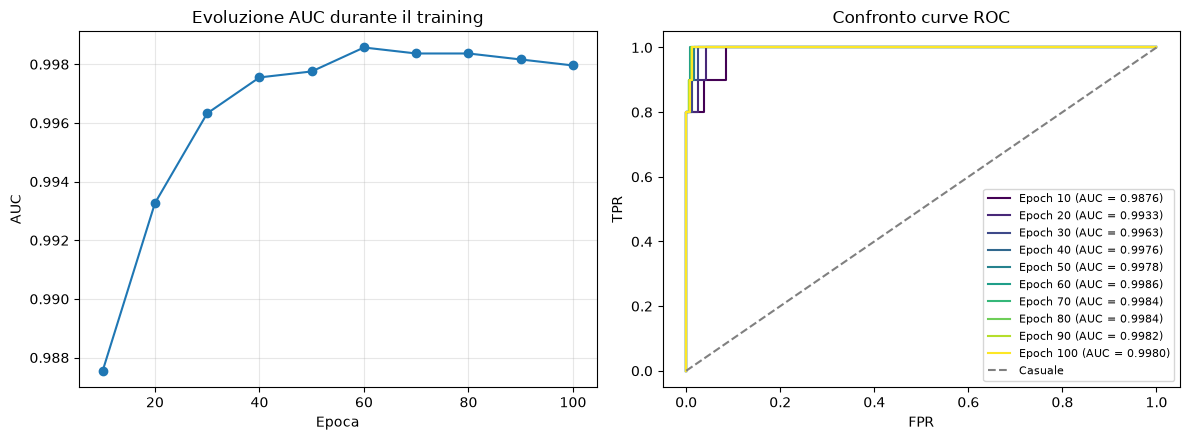

In [8]:
# EVOLUZIONE DURANTE IL TRAINING: AUC dei pesi salvati ogni CHECKPOINT_EVERY epoche
final_weights = copy.deepcopy(autoencoder.state_dict())
results = {}
for epoch, state_dict in sorted(checkpoints.items()):
    autoencoder.load_state_dict(state_dict)
    outlierness, labels = compute_outlierness(autoencoder, test_loader)
    fpr, tpr, _ = roc_curve(labels, outlierness)
    results[epoch] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc_score(labels, outlierness)}
    print(f"Epoch {epoch:3d}: AUC = {results[epoch]['auc']:.4f}")
autoencoder.load_state_dict(final_weights)   # ripristina il modello finale

epochs_list = list(results)
plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
plt.plot(epochs_list, [results[e]['auc'] for e in epochs_list], 'o-')
plt.xlabel('Epoca')
plt.ylabel('AUC')
plt.title('Evoluzione AUC durante il training')
plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2)
colors = plt.cm.viridis(np.linspace(0, 1, len(epochs_list)))
for epoch, color in zip(epochs_list, colors):
    plt.plot(results[epoch]['fpr'], results[epoch]['tpr'], color=color,
             label=f"Epoch {epoch} (AUC = {results[epoch]['auc']:.4f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Casuale')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Confronto curve ROC')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()